<a href="https://colab.research.google.com/github/Kusuma-Ramesh/real_estate_advisor/blob/main/Real_Estate_Investment_Advisor_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Real Estate Investment Advisor
### Predicting Property Profitability & Future Value

**Project:** Real Estate Investment Advisor  
**Domain:** Real Estate / Investment / Financial Analytics  
**Author:** Kusuma Ramesh  
**Repository:** [Kusuma-Ramesh/real_estate_advisor](https://github.com/Kusuma-Ramesh/real_estate_advisor)  
**Application:** Streamlit-based property screening and analytics

---

## Project summary

This notebook documents the end-to-end workflow implemented in the Real Estate Investment Advisor repository. It covers dataset loading and auditing, exploratory data analysis, feature engineering, target construction, model evaluation, saved-model inference, and assumption-based five-year scenarios.

### Important: distinguish the three output types

- **Learned:** The classifier learns to reproduce a rule-based proxy label. The current-price regressor learns against the observed `Price_in_Lakhs` target, but its measured performance is approximately the mean baseline.
- **Rule:** `Good_Investment` is generated from a deterministic eight-point checklist and a city-median price-per-square-foot condition.
- **Assumption:** The five-year projected price is calculated from an assumed annual growth rate. It is not learned from historical future prices and has no measured forecast accuracy.

> This is an educational screening and analytics prototype. It does not establish actual investment success, fair market value, or guaranteed future returns.

In [1]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.0,<4" "scikit-learn==1.8.0" "joblib>=1.3" "matplotlib>=3.8" "seaborn>=0.13" "plotly>=5.18"

In [2]:
from pathlib import Path
import os
import sys
import subprocess

REPO_URL = "https://github.com/Kusuma-Ramesh/real_estate_advisor.git"
REPO_DIR = Path("/content/real_estate_advisor")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)], check=True)
else:
    print("Repository directory already exists:", REPO_DIR)

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

print("Repository:", REPO_URL)
print("Working directory:", Path.cwd())
print("Top-level files:", sorted(p.name for p in REPO_DIR.iterdir())[:20])

Repository: https://github.com/Kusuma-Ramesh/real_estate_advisor.git
Working directory: /content/real_estate_advisor
Top-level files: ['.git', '.gitignore', '.streamlit', 'README.md', 'app.py', 'data', 'eda_outputs', 'models', 'reports', 'requirements.txt', 'smoke_test.py', 'src', 'tests']


## 2. Dataset upload and project constants

The project data file is named `india_housing_prices.csv` in local development, but it is not stored in GitHub. Use the file supplied for this project. The expected schema is enforced by `src/features.py`.

**Runtime-only upload:** The following cell uploads the CSV to `/content/project_input/`. It does not add the data to Git or modify the remote repository.

In [3]:
from pathlib import Path

INPUT_DIR = Path("/content/project_input")
INPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH = INPUT_DIR / "india_housing_prices.csv"

if not DATA_PATH.exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_names = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_names:
            raise FileNotFoundError("No CSV file was uploaded. Upload the Labmentix property listings CSV.")
        selected_name = csv_names[0]
        DATA_PATH = INPUT_DIR / Path(selected_name).name
        DATA_PATH.write_bytes(uploaded[selected_name])
    except ImportError:
        raise RuntimeError("Upload the compatible CSV to /content/project_input/india_housing_prices.csv.")

print("Dataset path:", DATA_PATH)
print("Dataset file exists:", DATA_PATH.exists())
print("Dataset size (MB):", round(DATA_PATH.stat().st_size / (1024**2), 2))

Saving india_housing_prices.csv to india_housing_prices.csv
Dataset path: /content/project_input/india_housing_prices.csv
Dataset file exists: True
Dataset size (MB): 39.21


In [4]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src.features import (
    REFERENCE_YEAR, HORIZON_YEARS, BASE_GROWTH, GROWTH_MIN, GROWTH_MAX,
    GOOD_SCORE_THRESHOLD, REQUIRED_COLS, clean, engineer, city_stats,
    investment_score, growth_rate, project_price, add_targets, prepare
)
from src.predict import load_artifacts, assess

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
import sklearn
print("scikit-learn:", sklearn.__version__)
print("Reference year:", REFERENCE_YEAR)
print("Projection horizon:", HORIZON_YEARS, "years")

Python: 3.13.18
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.8.0
Reference year: 2025
Projection horizon: 5 years


## 3. Dataset schema and initial inspection

The required fields describe location, property type, size, asking price, building details, neighbourhood indicators, amenities, ownership and availability. The source dataset does not contain historical sale dates, future prices, rental yield, or observed investment outcomes.

In [5]:
from src.features import load_raw, check_schema

raw = load_raw(DATA_PATH)
check_schema(raw)

print("Rows:", f"{len(raw):,}")
print("Columns:", raw.shape[1])
print("Required columns:", len(REQUIRED_COLS))
display(raw.head())
display(raw.dtypes.rename("dtype").to_frame())

Rows: 250,000
Columns: 23
Required columns: 20


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,...,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,...,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


,dtype
ID,int64
State,object
City,object
Locality,object
Property_Type,object
BHK,int64
Size_in_SqFt,int64
Price_in_Lakhs,float64
Price_per_SqFt,float64
Year_Built,int64


In [6]:
key_summary = raw[[
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Year_Built",
    "Floor_No", "Total_Floors", "Nearby_Schools", "Nearby_Hospitals"
]].describe().T
display(key_summary)

,count,mean,std,min,25%,50%,75%,max
BHK,250000.0,2.999396,1.415521,1.0,2.00,3.00,4.00,5.0
Size_in_SqFt,250000.0,2749.813216,1300.606954,500.0,1623.00,2747.00,3874.00,5000.0
Price_in_Lakhs,250000.0,254.586854,141.349921,10.0,132.55,253.87,376.88,500.0
Year_Built,250000.0,2006.520012,9.808575,1990.0,1998.00,2007.00,2015.00,2023.0
Floor_No,250000.0,14.966800,8.948047,0.0,7.00,15.00,23.00,30.0
Total_Floors,250000.0,15.503004,8.671618,1.0,8.00,15.00,23.00,30.0
Nearby_Schools,250000.0,5.499860,2.878639,1.0,3.00,5.00,8.00,10.0
Nearby_Hospitals,250000.0,5.498016,2.871860,1.0,3.00,5.00,8.00,10.0


## 4. Data-quality audit

This section invokes the repository's own audit module. It checks schema completeness, missing values, duplicate rows, impossible floor combinations, locality identifiers, numeric correlations, uniform distributions and implausible combinations.

The audit deliberately flags questionable records rather than silently inventing corrected values.

In [7]:
from src.audit import main as run_data_audit

run_data_audit(path=str(DATA_PATH))
audit_report_path = REPO_DIR / "reports" / "data_audit.md"
if audit_report_path.exists():
    print("\nSaved audit report:", audit_report_path)
    print(audit_report_path.read_text(encoding="utf-8")[:9000])

# Data audit (generated by `python -m src.audit`)

- **Rows / columns:** 250,000 / 23
- **Missing values (total cells):** 0
- **Rows with non-positive size or price:** 0
- **Missing required columns:** none
- **Duplicate rows ignoring ID:** 0
- **Date consistency:** Age_of_Property + Year_Built takes values [2025] (reference year 2025); Year_Built range 1990-2023. The pipeline recomputes age from Year_Built against this single reference year.
- **Floor_No > Total_Floors:** 116,304 rows (46.5%) - impossible physically; kept and flagged via `Floor_Inconsistent`, ratio capped at 1. Dropping them would discard almost half the data; repairing them would invent data.
- **Floor_No == 0 (ground floor):** 8,203 rows - valid
- **Source Price_per_SqFt:** in lakhs, rounded to 2 dp (2,534 rows are 0.0, max rounding error 0.005 lakh/sqft); recomputed in rupees/sqft as `Price_per_SqFt_Rs`.
- **Locality ids:** 500 ids; 500 appear in more than one city (median 42 cities) -> not a geographic hierarchy; 

In [8]:
audit_indicators = pd.Series({
    "Rows": len(raw),
    "Columns": raw.shape[1],
    "Missing cells": int(raw.isna().sum().sum()),
    "Duplicate rows (ignoring ID)": int(raw.drop(columns=["ID"], errors="ignore").duplicated().sum()),
    "Non-positive size or price": int(((raw["Size_in_SqFt"] <= 0) | (raw["Price_in_Lakhs"] <= 0)).sum()),
    "Floor_No > Total_Floors": int((raw["Floor_No"] > raw["Total_Floors"]).sum()),
    "Distinct cities": raw["City"].nunique(),
    "Distinct states": raw["State"].nunique(),
    "Distinct locality IDs": raw["Locality"].nunique(),
})
display(audit_indicators.to_frame("Observed value"))

,Observed value
Rows,250000
Columns,23
Missing cells,0
Duplicate rows (ignoring ID),0
Non-positive size or price,0
Floor_No > Total_Floors,116304
Distinct cities,42
Distinct states,20
Distinct locality IDs,500


### Dataset audit interpretation

The repository audit recorded 250,000 rows and 23 columns, no missing cells, no duplicate rows (ignoring ID), and no non-positive size/price rows. It also identified substantial quality limitations:

- 116,304 rows (46.5%) have `Floor_No > Total_Floors`; these are retained and flagged rather than fabricated or discarded.
- All 500 locality IDs occur in more than one city, so locality is excluded from model inputs.
- The largest absolute correlation among raw numeric attributes is approximately 0.0059, indicating near-independent columns.
- Numeric columns and categorical shares are unusually uniform/balanced, which is consistent with synthetic data.

These observations constrain what can be inferred from the data.

## 5. Exploratory data analysis — 20 project questions

The following charts mirror the 20-question EDA implemented in `src/eda.py` and documented in `eda_outputs/findings.md`. Charts are generated from the uploaded CSV. Interpretations are specific to this dataset, not general real-estate market claims.

In [9]:
cleaned = clean(raw)
features_df = engineer(cleaned)
eda_stats = city_stats(features_df)
eda_df = add_targets(features_df, eda_stats)
eda_df["PPSF"] = eda_df["Price_per_SqFt_Rs"]

print("Rows after project cleaning:", f"{len(eda_df):,}")
print("Columns after feature engineering and descriptive targets:", eda_df.shape[1])
display(eda_df.head(3))

Rows after project cleaning: 250,000
Columns after feature engineering and descriptive targets: 34


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,...,Floor_Inconsistent,Floor_Ratio,Amenity_Count,Infra_Score,School_Density_Score,Growth_Rate,Projected_Price_5Y_Lakhs,Investment_Score,Good_Investment,PPSF
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,...,1,1.000000,5,7.55,2.109705,0.085600,738.469368,3,0,10332.489451
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,...,1,1.000000,5,3.15,3.384095,0.082086,290.067790,4,0,8270.727580
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,...,0,0.703704,4,5.95,2.471170,0.065900,252.874006,4,0,5046.403075


### Q1. Distribution of property asking prices

**Why:** Inspect the range, centre and shape of the observed asking-price column.

**Project finding:** The reference file is roughly uniform from ₹10 lakh to ₹500 lakh (mean around ₹255 lakh; median around ₹254 lakh), unlike a typical long-tailed market distribution.

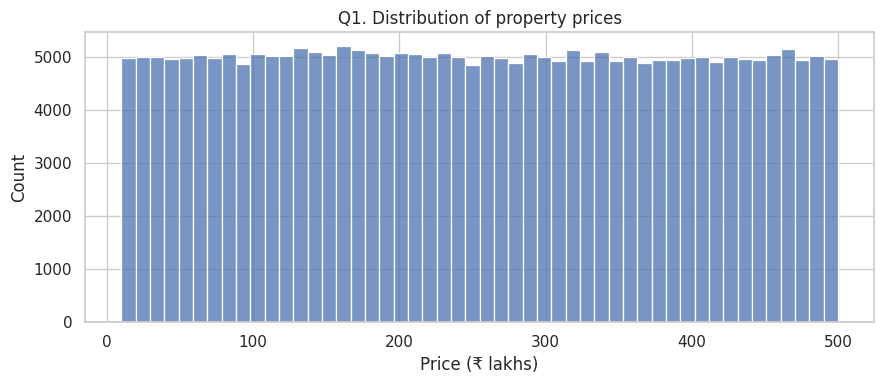

In [10]:
plt.figure(figsize=(9, 4))
sns.histplot(eda_df["Price_in_Lakhs"], bins=50)
plt.title("Q1. Distribution of property prices")
plt.xlabel("Price (₹ lakhs)")
plt.tight_layout()
plt.show()

### Q2. Distribution of property sizes

**Why:** Review the size range and concentration of listing records.

**Project finding:** Size values are roughly uniform over 500–5,000 sq ft, with a median near 2,747 sq ft.

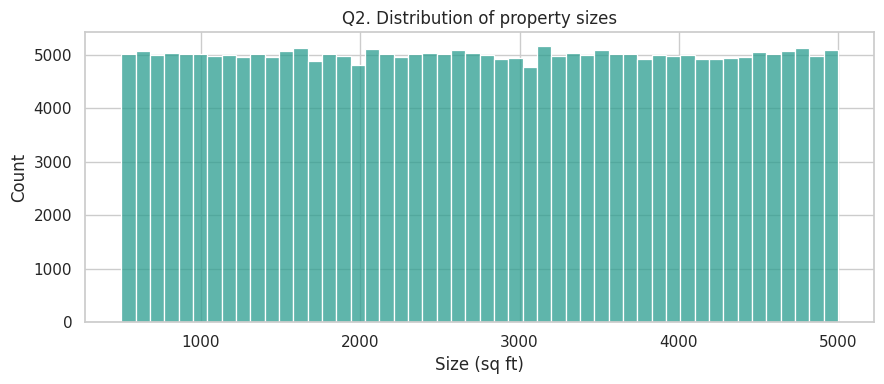

In [11]:
plt.figure(figsize=(9, 4))
sns.histplot(eda_df["Size_in_SqFt"], bins=50, color="#2A9D8F")
plt.title("Q2. Distribution of property sizes")
plt.xlabel("Size (sq ft)")
plt.tight_layout()
plt.show()

### Q3. Price per square foot by property type

**Why:** Compare median asking price per sq ft across property types.

**Project finding:** Median values are close: Apartment ₹9,245, Independent House ₹9,305, Villa ₹9,190 per sq ft. Differences are small in this dataset.

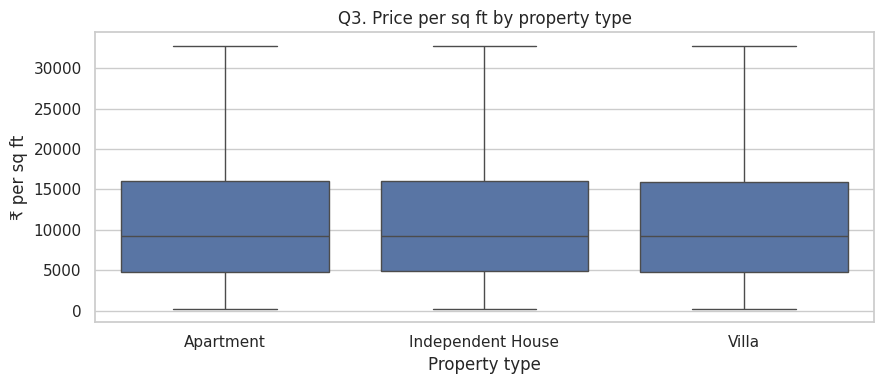

In [12]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=eda_df, x="Property_Type", y="PPSF", showfliers=False)
plt.title("Q3. Price per sq ft by property type")
plt.xlabel("Property type"); plt.ylabel("₹ per sq ft")
plt.tight_layout()
plt.show()

### Q4. Property size versus asking price

**Why:** Examine whether larger properties are associated with higher asking prices.

**Project finding:** The raw correlation between size and price is approximately −0.003, effectively no relationship. The negative relationship between size and price per sq ft is largely a mathematical consequence of the ratio.

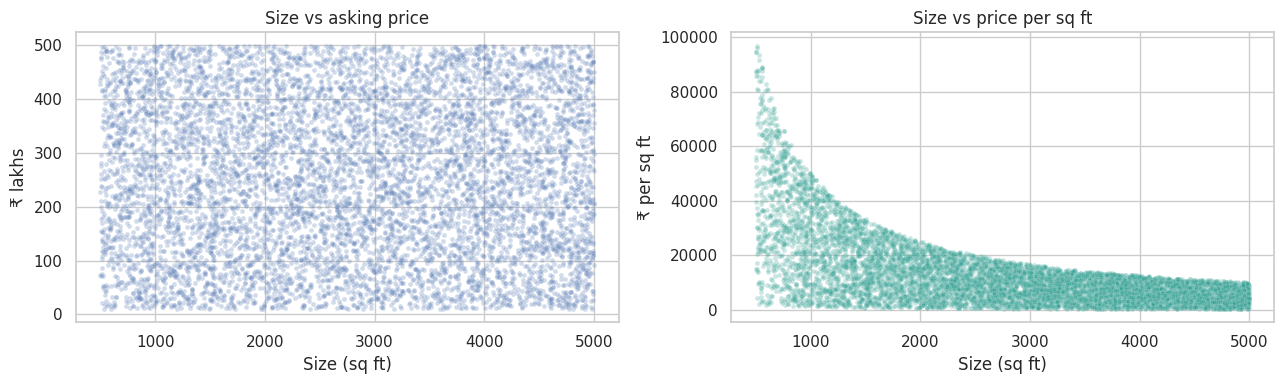

Correlation (size, price): -0.0025
Correlation (size, price per sq ft): -0.615


In [13]:
sample_q4 = eda_df.sample(min(8000, len(eda_df)), random_state=RANDOM_STATE)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=sample_q4, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=.25, s=12, ax=ax[0])
ax[0].set_title("Size vs asking price"); ax[0].set_xlabel("Size (sq ft)"); ax[0].set_ylabel("₹ lakhs")
sns.scatterplot(data=sample_q4, x="Size_in_SqFt", y="PPSF", alpha=.25, s=12, ax=ax[1], color="#2A9D8F")
ax[1].set_title("Size vs price per sq ft"); ax[1].set_xlabel("Size (sq ft)"); ax[1].set_ylabel("₹ per sq ft")
plt.tight_layout()
plt.show()
print("Correlation (size, price):", round(eda_df["Size_in_SqFt"].corr(eda_df["Price_in_Lakhs"]), 4))
print("Correlation (size, price per sq ft):", round(eda_df["Size_in_SqFt"].corr(eda_df["PPSF"]), 3))

### Q5. Price-per-square-foot outliers

**Why:** Identify unusually high price-per-square-foot observations.

**Project finding:** About 7.9% are high-side IQR outliers; these are retained as observed records rather than automatically removed.

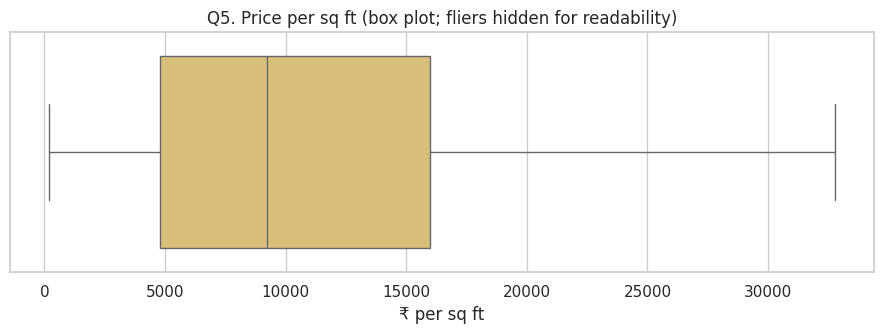

High-side IQR outlier share: 7.9%


In [14]:
plt.figure(figsize=(9, 3.5))
sns.boxplot(x=eda_df["PPSF"], showfliers=False, color="#E9C46A")
plt.title("Q5. Price per sq ft (box plot; fliers hidden for readability)")
plt.xlabel("₹ per sq ft")
plt.tight_layout()
plt.show()
q1, q3 = eda_df["PPSF"].quantile([.25, .75])
iqr = q3 - q1
print("High-side IQR outlier share:", f"{(eda_df['PPSF'] > q3 + 1.5*iqr).mean():.1%}")

### Q6. Price per square foot by state

**Why:** Compare state-level average price per sq ft.

**Project finding:** The reference analysis found a narrow range across states (about ₹12,931–₹13,252 per sq ft), roughly a 2% spread.

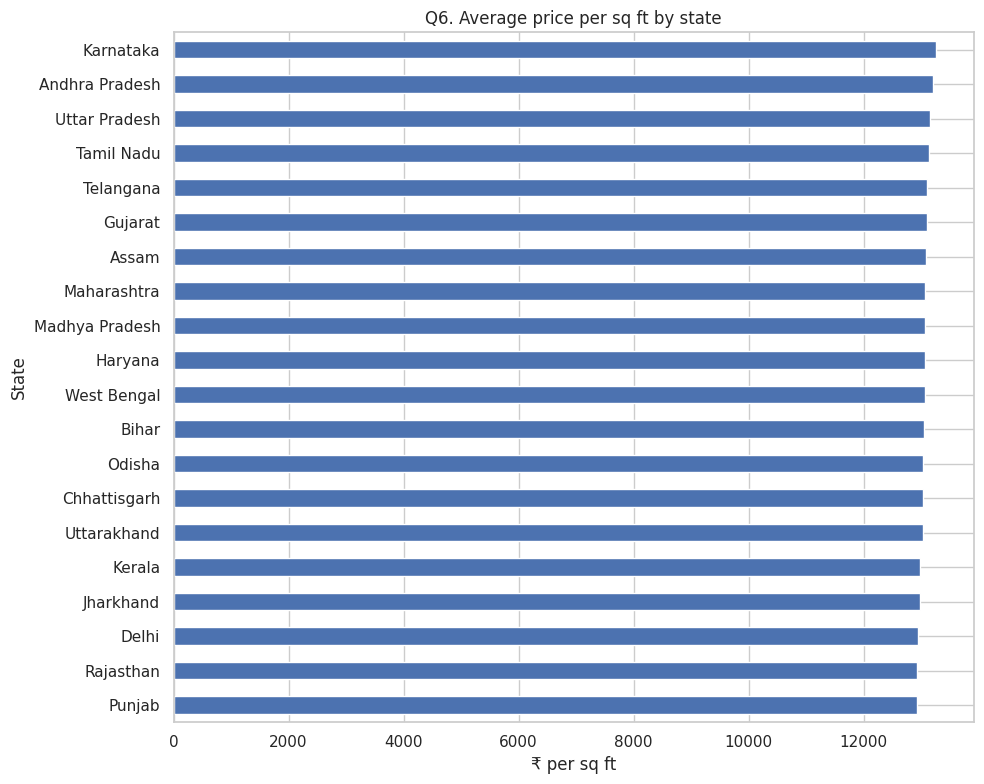

In [15]:
state_ppsf = eda_df.groupby("State")["PPSF"].mean().sort_values()
plt.figure(figsize=(10, 8))
state_ppsf.plot(kind="barh")
plt.title("Q6. Average price per sq ft by state")
plt.xlabel("₹ per sq ft")
plt.tight_layout()
plt.show()

### Q7. Asking price by city

**Why:** Compare average listing prices across cities.

**Project finding:** The recorded range was approximately ₹251–₹258 lakh, a very flat spread.

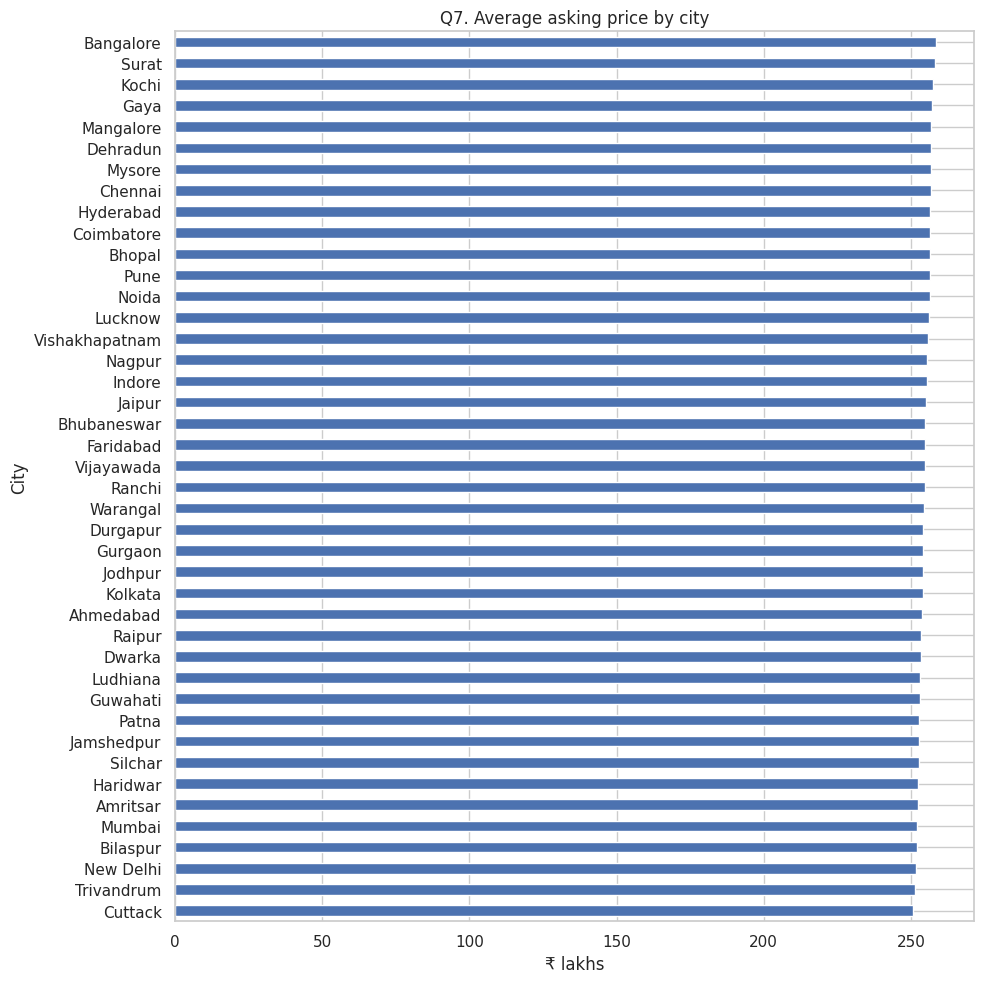

In [16]:
city_price = eda_df.groupby("City")["Price_in_Lakhs"].mean().sort_values()
plt.figure(figsize=(10, 10))
city_price.plot(kind="barh")
plt.title("Q7. Average asking price by city")
plt.xlabel("₹ lakhs")
plt.tight_layout()
plt.show()

### Q8. Property age by locality ID

**Why:** Explore the distribution of property age across locality identifiers.

**Caveat:** Locality IDs repeat across cities and do not represent a city-specific geographic hierarchy. Apparent differences should not be treated as neighbourhood effects.

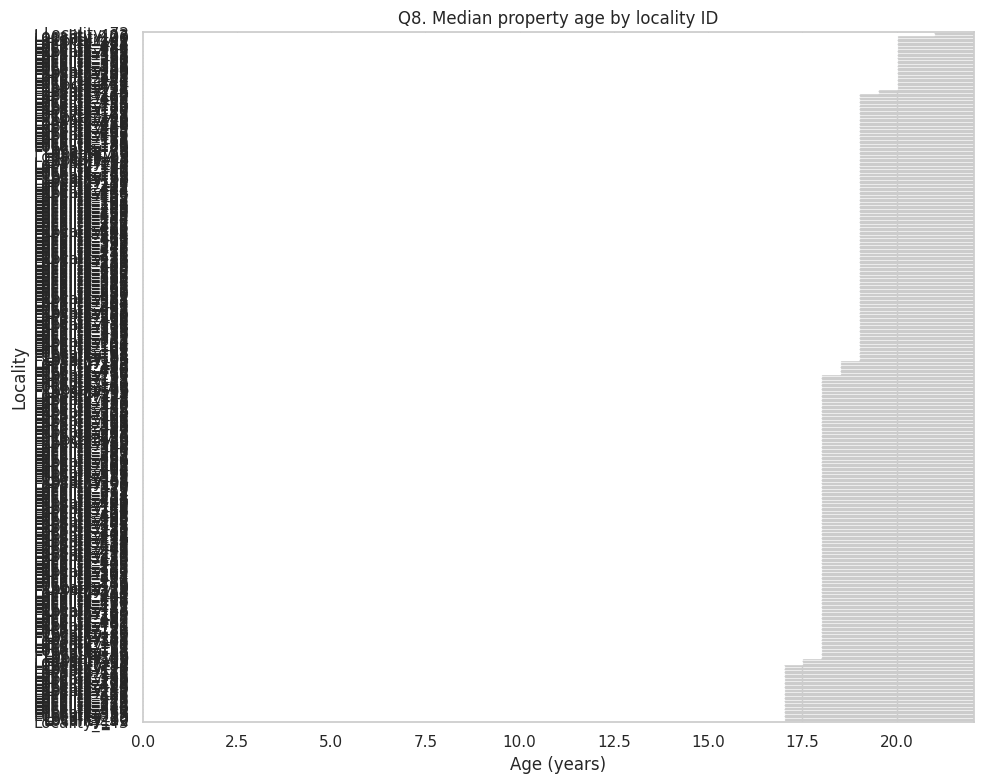

Locality IDs appearing in multiple cities: 500


In [17]:
locality_age = eda_df.groupby("Locality")["Age_of_Property"].median().sort_values()
plt.figure(figsize=(10, 8))
locality_age.plot(kind="barh")
plt.title("Q8. Median property age by locality ID")
plt.xlabel("Age (years)")
plt.tight_layout()
plt.show()
print("Locality IDs appearing in multiple cities:", int((raw.groupby("Locality")["City"].nunique() > 1).sum()))

### Q9. BHK distribution by city

**Why:** Check whether cities have different bedroom-count compositions.

**Project finding:** BHK values are near-uniform in each city; the maximum deviation from a 20% share was approximately 2%.

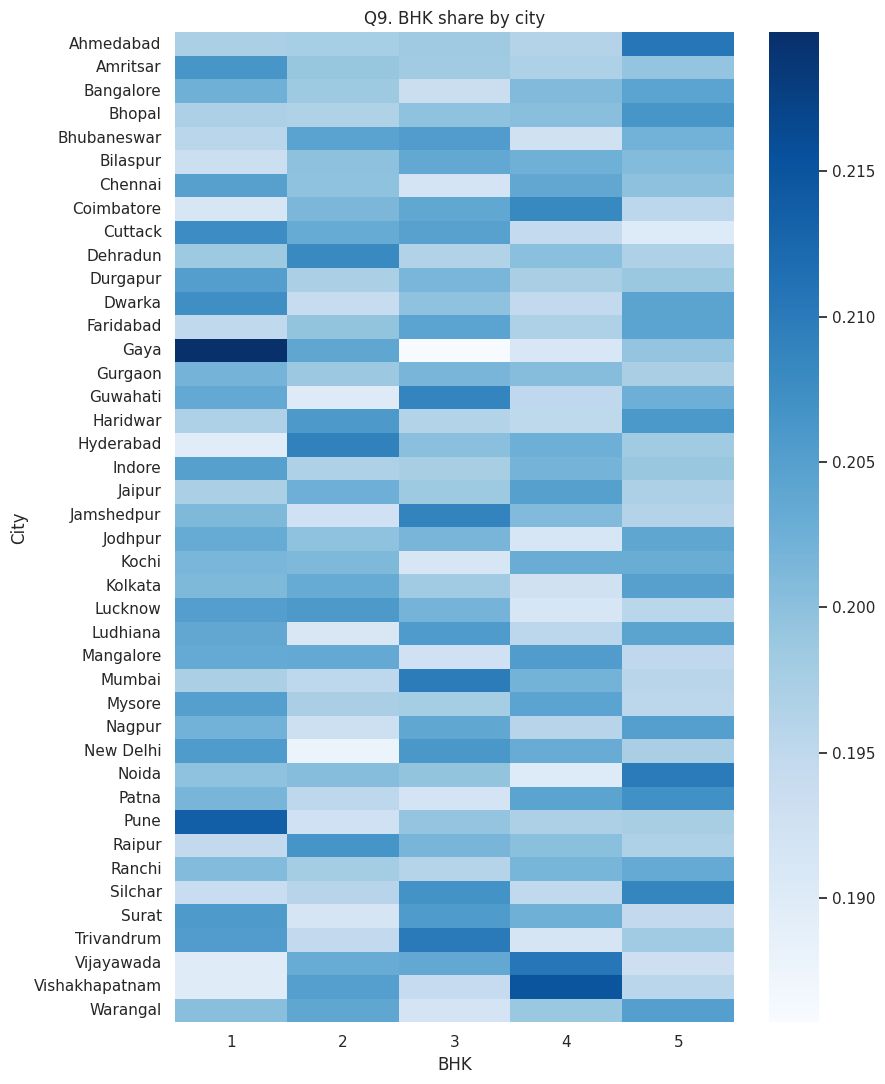

In [18]:
bhk_city = pd.crosstab(eda_df["City"], eda_df["BHK"], normalize="index")
plt.figure(figsize=(9, 11))
sns.heatmap(bhk_city, cmap="Blues", annot=False)
plt.title("Q9. BHK share by city")
plt.xlabel("BHK"); plt.ylabel("City")
plt.tight_layout()
plt.show()

### Q10. Localities with the highest median price per sq ft

**Why:** Rank locality IDs with a minimum number of records.

**Caveat:** Locality IDs occur across many cities and cannot be interpreted as real neighbourhoods. The ranking is descriptive and may be sampling noise.

,median_ppsf,listings
Locality,,
Locality_146,10410.865874,513
Locality_207,10405.250757,467
Locality_164,10321.006365,504
Locality_44,10294.921371,505
Locality_360,10270.072993,505
Locality_315,10227.803293,498
Locality_416,10165.870526,478
Locality_177,10147.807677,500
Locality_93,10087.534053,530


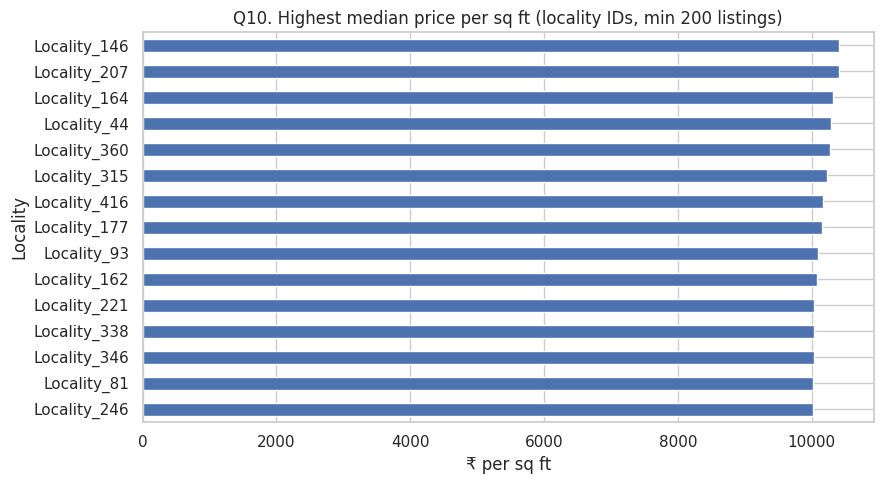

In [19]:
locality_summary = eda_df.groupby("Locality").agg(
    median_ppsf=("PPSF", "median"),
    listings=("PPSF", "size")
)
locality_summary = locality_summary[locality_summary["listings"] >= 200].sort_values("median_ppsf").tail(15)
display(locality_summary.sort_values("median_ppsf", ascending=False))
plt.figure(figsize=(9, 5))
locality_summary["median_ppsf"].sort_values().plot(kind="barh")
plt.title("Q10. Highest median price per sq ft (locality IDs, min 200 listings)")
plt.xlabel("₹ per sq ft")
plt.tight_layout()
plt.show()

### Q11. Correlation among selected numeric attributes

**Why:** Identify relationships among raw numeric variables and distinguish derived mathematical relationships from substantive signal.

**Project finding:** The largest absolute correlation among raw, non-derived attributes is approximately 0.0059. Stronger correlations involve derived ratios or scores.

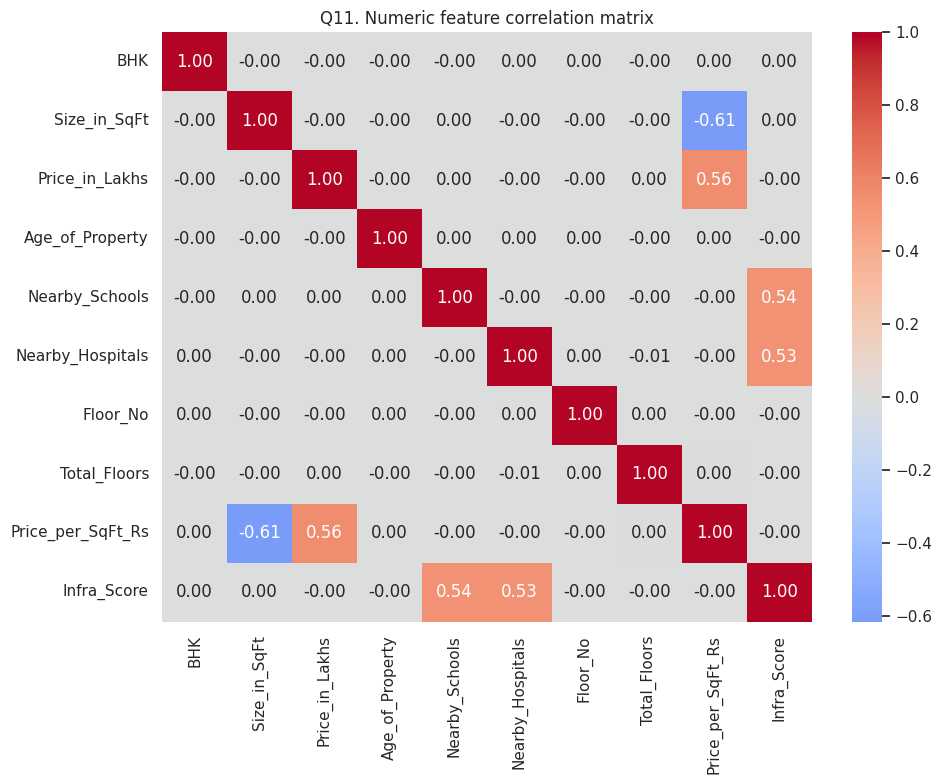

In [20]:
raw_numeric = eda_df[[
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Age_of_Property",
    "Nearby_Schools", "Nearby_Hospitals", "Floor_No", "Total_Floors",
    "Price_per_SqFt_Rs", "Infra_Score"
]]
plt.figure(figsize=(10, 8))
sns.heatmap(raw_numeric.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Q11. Numeric feature correlation matrix")
plt.tight_layout()
plt.show()

### Q12. Nearby schools versus price per sq ft

**Why:** Check whether school counts are associated with listing price per sq ft.

**Project finding:** The correlation is approximately zero; no meaningful relationship appears in this dataset.

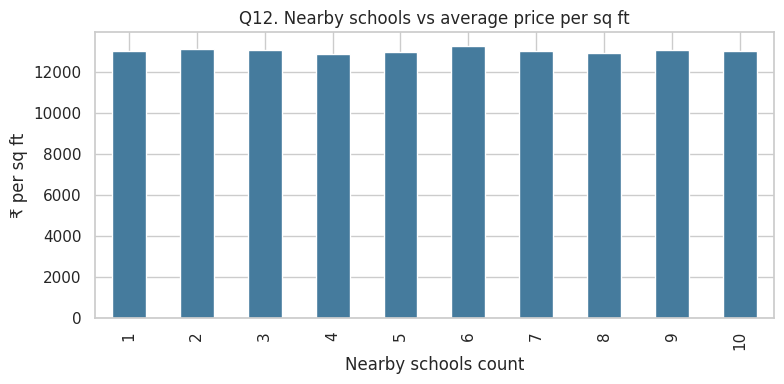

Correlation: -0.0001


In [21]:
schools_ppsf = eda_df.groupby("Nearby_Schools")["PPSF"].mean()
plt.figure(figsize=(8, 4))
schools_ppsf.plot(kind="bar", color="#457B9D")
plt.title("Q12. Nearby schools vs average price per sq ft")
plt.xlabel("Nearby schools count"); plt.ylabel("₹ per sq ft")
plt.tight_layout()
plt.show()
print("Correlation:", round(eda_df["Nearby_Schools"].corr(eda_df["PPSF"]), 4))

### Q13. Nearby hospitals versus price per sq ft

**Why:** Check whether hospital counts are associated with price per sq ft.

**Project finding:** The correlation is approximately zero; no meaningful relationship appears in this dataset.

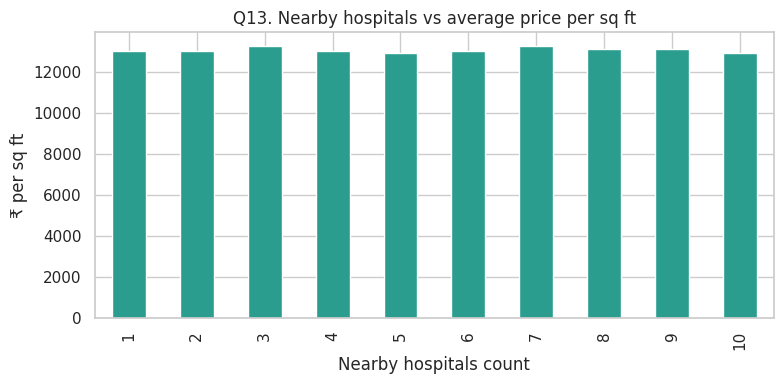

Correlation: -0.0001


In [22]:
hospitals_ppsf = eda_df.groupby("Nearby_Hospitals")["PPSF"].mean()
plt.figure(figsize=(8, 4))
hospitals_ppsf.plot(kind="bar", color="#2A9D8F")
plt.title("Q13. Nearby hospitals vs average price per sq ft")
plt.xlabel("Nearby hospitals count"); plt.ylabel("₹ per sq ft")
plt.tight_layout()
plt.show()
print("Correlation:", round(eda_df["Nearby_Hospitals"].corr(eda_df["PPSF"]), 4))

### Q14. Asking price by furnishing status

**Why:** Compare mean asking prices across furnishing categories.

**Project finding:** Mean prices differ by less than 1% across furnished, semi-furnished and unfurnished records.

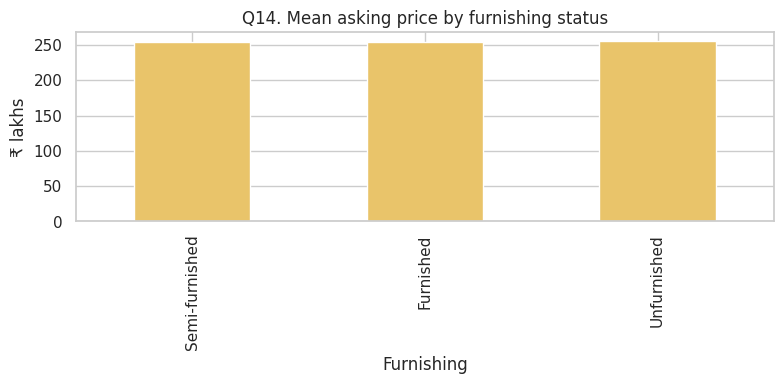

,Mean price (₹ lakhs)
Furnished_Status,
Semi-furnished,254.334836
Furnished,254.445550
Unfurnished,254.979752


In [23]:
furn_price = eda_df.groupby("Furnished_Status")["Price_in_Lakhs"].mean().sort_values()
plt.figure(figsize=(8, 4))
furn_price.plot(kind="bar", color="#E9C46A")
plt.title("Q14. Mean asking price by furnishing status")
plt.xlabel("Furnishing"); plt.ylabel("₹ lakhs")
plt.tight_layout()
plt.show()
display(furn_price.to_frame("Mean price (₹ lakhs)"))

### Q15. Price per sq ft by facing

**Why:** Compare mean price per sq ft by property-facing direction.

**Project finding:** Values are effectively identical across facing directions.

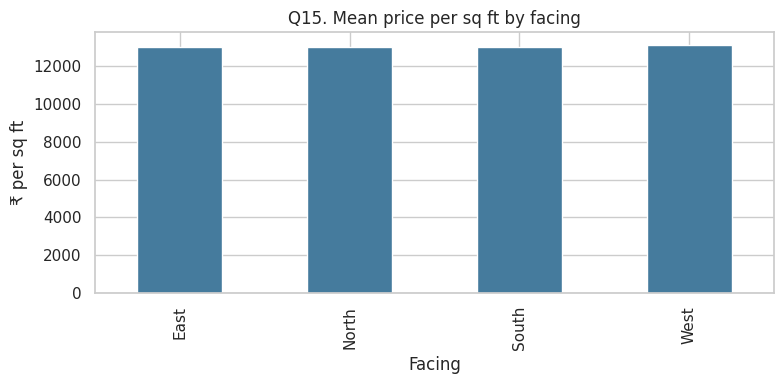

In [24]:
facing_ppsf = eda_df.groupby("Facing")["PPSF"].mean().sort_values()
plt.figure(figsize=(8, 4))
facing_ppsf.plot(kind="bar", color="#457B9D")
plt.title("Q15. Mean price per sq ft by facing")
plt.xlabel("Facing"); plt.ylabel("₹ per sq ft")
plt.tight_layout()
plt.show()

### Q16. Listings by owner type

**Why:** Inspect the owner-type composition of the dataset.

**Project finding:** Broker, owner and builder categories are almost evenly represented.

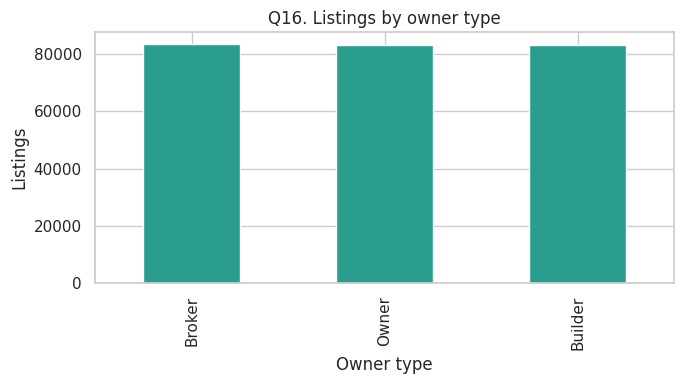

In [25]:
owner_counts = eda_df["Owner_Type"].value_counts()
plt.figure(figsize=(7, 4))
owner_counts.plot(kind="bar", color="#2A9D8F")
plt.title("Q16. Listings by owner type")
plt.xlabel("Owner type"); plt.ylabel("Listings")
plt.tight_layout()
plt.show()

### Q17. Listings by availability status

**Why:** Compare ready-to-move and under-construction listings.

**Project finding:** The two statuses are represented almost exactly 50/50. The source data has no sold status.

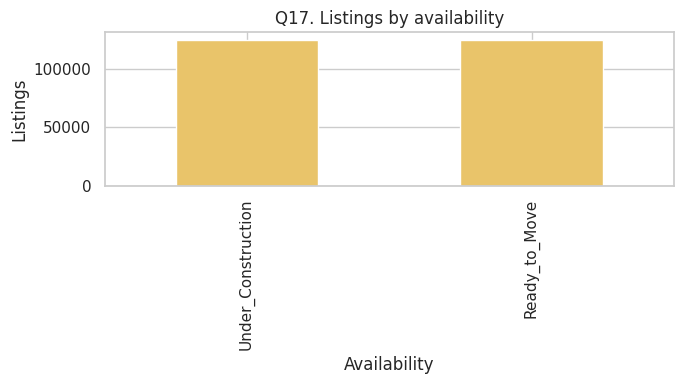

In [26]:
availability_counts = eda_df["Availability_Status"].value_counts()
plt.figure(figsize=(7, 4))
availability_counts.plot(kind="bar", color="#E9C46A")
plt.title("Q17. Listings by availability")
plt.xlabel("Availability"); plt.ylabel("Listings")
plt.tight_layout()
plt.show()

### Q18. Asking price by parking availability

**Why:** Compare average asking price for listings with and without parking.

**Project finding:** Mean prices are very close, with no meaningful effect visible in this dataset.

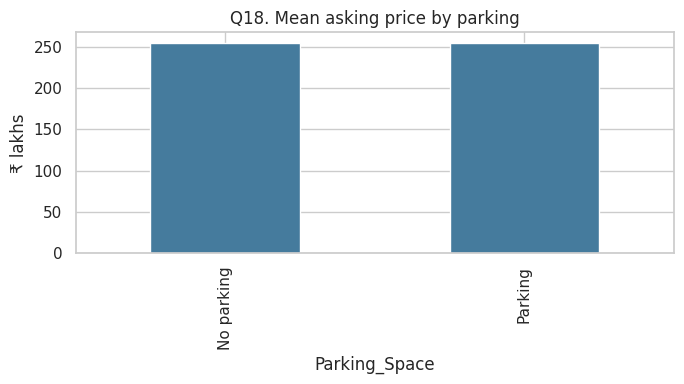

In [27]:
parking_price = eda_df.groupby("Parking_Space")["Price_in_Lakhs"].mean()
plt.figure(figsize=(7, 4))
parking_price.rename({0: "No parking", 1: "Parking"}).plot(kind="bar", color="#457B9D")
plt.title("Q18. Mean asking price by parking")
plt.ylabel("₹ lakhs")
plt.tight_layout()
plt.show()

### Q19. Amenities versus price per sq ft

**Why:** Compare the mean price per sq ft associated with amenity tokens.

**Project finding:** The mean price per sq ft spread across amenity types is only about 0.4%; amenity count is not a meaningful price driver in this dataset.

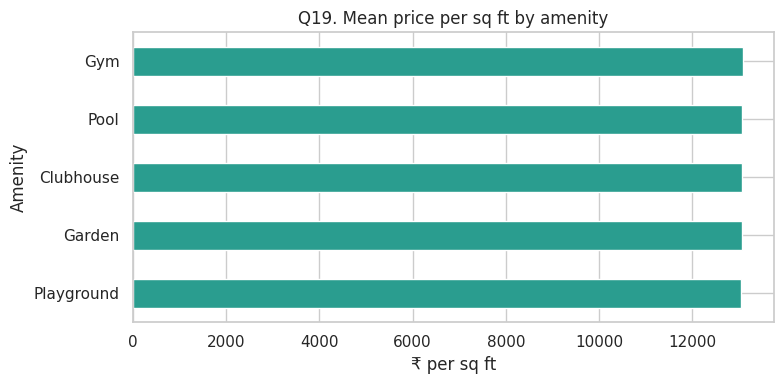

In [28]:
amenity_rows = eda_df[["PPSF", "Amenities"]].copy()
amenity_rows["Amenity"] = amenity_rows["Amenities"].fillna("None").str.split(",")
amenity_rows = amenity_rows.explode("Amenity")
amenity_rows["Amenity"] = amenity_rows["Amenity"].str.strip()
amenity_rows = amenity_rows[amenity_rows["Amenity"].ne("None")]
amenity_ppsf = amenity_rows.groupby("Amenity")["PPSF"].mean().sort_values()
plt.figure(figsize=(8, 4))
amenity_ppsf.plot(kind="barh", color="#2A9D8F")
plt.title("Q19. Mean price per sq ft by amenity")
plt.xlabel("₹ per sq ft")
plt.tight_layout()
plt.show()

### Q20. Public transport accessibility

**Why:** Compare price per sq ft and the share receiving the rule-based label across transport levels.

**Project finding:** Price per sq ft is relatively flat. The proxy-label rate rises with transport access because the checklist explicitly awards a point for Medium/High transport. This is a rule effect, not evidence of market performance.

,mean_ppsf,proxy_label_rate
Public_Transport_Accessibility,,
Low,13085.539062,0.195673
Medium,13062.233115,0.348340
High,13027.242169,0.353922


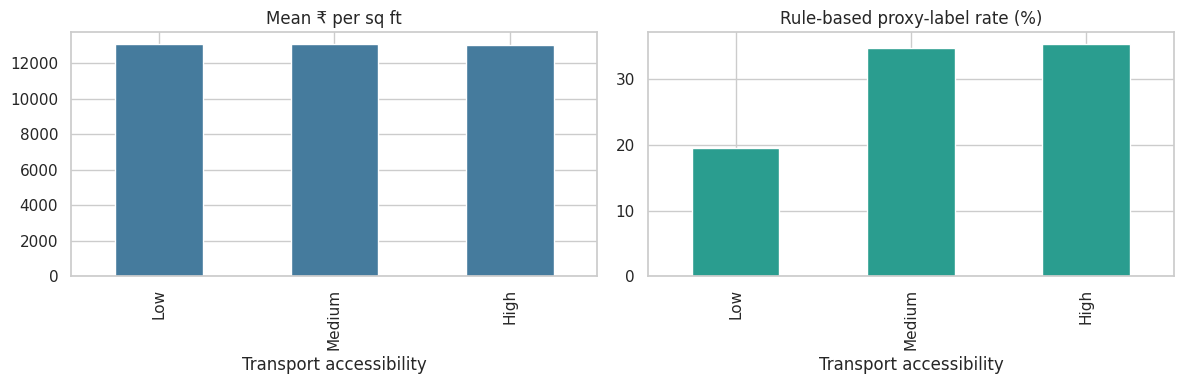

In [29]:
transport_summary = eda_df.groupby("Public_Transport_Accessibility").agg(
    mean_ppsf=("PPSF", "mean"),
    proxy_label_rate=("Good_Investment", "mean")
).reindex(["Low", "Medium", "High"])
display(transport_summary)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
transport_summary["mean_ppsf"].plot(kind="bar", ax=axes[0], color="#457B9D", title="Mean ₹ per sq ft")
transport_summary["proxy_label_rate"].mul(100).plot(kind="bar", ax=axes[1], color="#2A9D8F", title="Rule-based proxy-label rate (%)")
for ax in axes:
    ax.set_xlabel("Transport accessibility")
plt.tight_layout()
plt.show()

## 6. Cleaning and feature engineering

The notebook now uses the same functions as the project application:

- `clean()` checks required columns, removes exact duplicates, drops rows missing essential values, and filters non-positive size/price.
- `engineer()` recomputes age from the 2025 reference year, recomputes price per sq ft in rupees, flags inconsistent floor counts, caps floor ratio, converts parking/security to indicators, counts amenities, and constructs infrastructure and school-density scores.

The original `Price_per_SqFt` column is not trusted as-is because it is rounded in the source. `Price_per_SqFt_Rs` is recomputed from price and size.

In [30]:
model_ready = engineer(clean(raw))
print("Model-ready rows:", f"{len(model_ready):,}")
feature_preview = [
    "Age_of_Property", "Price_per_SqFt_Rs", "Floor_Inconsistent", "Floor_Ratio",
    "Parking_Space", "Security", "Amenity_Count", "Infra_Score", "School_Density_Score"
]
display(model_ready[feature_preview].describe().T)

Model-ready rows: 250,000


,count,mean,std,min,25%,50%,75%,max
Age_of_Property,250000.0,18.479988,9.808575,2.000000,10.000000,18.000000,27.000000,35.0
Price_per_SqFt_Rs,250000.0,13058.281776,13071.850480,202.247191,4802.839710,9244.747594,15987.388517,99182.0
Floor_Inconsistent,250000.0,0.465216,0.498790,0.000000,0.000000,0.000000,1.000000,1.0
Floor_Ratio,250000.0,0.732545,0.336070,0.000000,0.466667,0.964286,1.000000,1.0
Parking_Space,250000.0,0.498176,0.499998,0.000000,0.000000,0.000000,1.000000,1.0
Security,250000.0,0.500932,0.500000,0.000000,0.000000,1.000000,1.000000,1.0
Amenity_Count,250000.0,3.000288,1.414284,1.000000,2.000000,3.000000,4.000000,5.0
Infra_Score,250000.0,5.351765,1.877178,0.700000,3.950000,5.350000,6.750000,10.0
School_Density_Score,250000.0,2.815373,2.740424,0.200000,1.091107,1.999556,3.423485,20.0


### Engineered-feature definitions

| Feature | Project construction |
|---|---|
| `Age_of_Property` | `2025 - Year_Built` |
| `Price_per_SqFt_Rs` | `Price_in_Lakhs × 100,000 / Size_in_SqFt` |
| `Floor_Inconsistent` | 1 when `Floor_No > Total_Floors`, otherwise 0 |
| `Floor_Ratio` | `Floor_No / max(Total_Floors, 1)`, capped at 1 |
| `Parking_Space`, `Security` | Yes/No values converted to 1/0 |
| `Amenity_Count` | Number of comma-separated amenity tokens |
| `Infra_Score` | 0.35 × schools + 0.35 × hospitals + 0.30 × transport score × 5 |
| `School_Density_Score` | Schools divided by property size in thousands of sq ft |

`Locality` remains available for filtering and EDA but is excluded from model inputs because locality IDs are not city-specific geographic identifiers.

## 7. Rule-based target and assumption-based projection

The project has no observed `Good_Investment` column. The label is constructed from:
1. Price per sq ft at or below the city's median, and
2. An eight-point checklist score of at least 5.

The five-year projection is calculated as:

\[
P_{2030} = P_{2025}(1+r)^5
\]

where the annual rate is an assumption constructed from fixed adjustments and clipped between 4% and 12%. The base assumption is 8%.

In [31]:
score, checklist = investment_score(eda_df, eda_stats)
proxy_rate = eda_df["Good_Investment"].mean()

print("Checklist score range:", int(score.min()), "to", int(score.max()), "out of 8")
print("Rule threshold:", GOOD_SCORE_THRESHOLD, "/ 8, plus price/sq-ft <= city median")
print("Good_Investment proxy-label share:", f"{proxy_rate:.2%}")
display(checklist.mean().rename("Share satisfying condition").to_frame())

Checklist score range: 0 to 8 out of 8
Rule threshold: 5 / 8, plus price/sq-ft <= city median
Good_Investment proxy-label share: 29.93%


,Share satisfying condition
cheaper_than_city_median,0.500052
bhk_3plus,0.599956
ready_to_move,0.499860
good_transport,0.666852
security,0.500932
parking,0.498176
social_infra,0.550000
young_building,0.500272


In [32]:
growth = growth_rate(eda_df, eda_stats)
eda_df["Growth_Rate"] = growth
eda_df["Projected_Price_5Y_Lakhs"] = project_price(eda_df["Price_in_Lakhs"], growth)

print("Assumed annual growth range:", f"{growth.min():.2%} to {growth.max():.2%}")
print("Base annual growth assumption:", f"{BASE_GROWTH:.0%}")
print("Projection target year:", REFERENCE_YEAR + HORIZON_YEARS)
display(eda_df[["Price_in_Lakhs", "Growth_Rate", "Projected_Price_5Y_Lakhs"]].head())

Assumed annual growth range: 4.10% to 11.33%
Base annual growth assumption: 8%
Projection target year: 2030


,Price_in_Lakhs,Growth_Rate,Projected_Price_5Y_Lakhs
0,489.76,0.085600,738.469368
1,195.52,0.082086,290.067790
2,183.79,0.065900,252.874006
3,300.29,0.075971,433.056504
4,182.90,0.066171,251.970040


## 8. Leak-free model evaluation setup

The repository's training pipeline uses an 80/20 train/test split with random seed 42. The split is performed **before** city statistics and proxy labels are constructed. City medians for the proxy label are computed from training rows only.

- Train rows: 200,000
- Held-out test rows: 50,000
- Seed: 42
- Classification target: rule-based `Good_Investment`
- Regression target: observed current `Price_in_Lakhs`
- The regressor excludes both `Price_in_Lakhs` and the derived `Price_per_SqFt_Rs`.

The cell below reproduces the split and target preparation logic for inspection. The saved evaluation report remains the source of the recorded test metrics.

In [33]:
from sklearn.model_selection import train_test_split
from src.features import CLS_FEATURES, REG_FEATURES, MODEL_CATS, add_targets, city_stats

train_base, test_base = train_test_split(
    model_ready, test_size=0.2, random_state=42
)
train_stats = city_stats(train_base)
train_eval = add_targets(train_base, train_stats)
test_eval = add_targets(test_base, train_stats)

print("Train rows:", f"{len(train_eval):,}")
print("Test rows:", f"{len(test_eval):,}")
print("Train proxy-label rate:", f"{train_eval['Good_Investment'].mean():.4f}")
print("Test proxy-label rate:", f"{test_eval['Good_Investment'].mean():.4f}")
print("Classifier feature count:", len(CLS_FEATURES))
print("Regressor feature count:", len(REG_FEATURES))
print("Price columns excluded from regressor:", set(["Price_in_Lakhs", "Price_per_SqFt_Rs"]).isdisjoint(REG_FEATURES))

Train rows: 200,000
Test rows: 50,000
Train proxy-label rate: 0.2992
Test proxy-label rate: 0.2992
Classifier feature count: 24
Regressor feature count: 22
Price columns excluded from regressor: True


### Feature and target design

**Classifier inputs:** categorical project attributes plus all engineered numeric attributes, including price-per-square-foot because the rule-based target depends on it. This makes it a rule-recovery task.

**Regressor inputs:** the same categorical attributes plus non-price engineered numeric attributes. It excludes `Price_in_Lakhs` and `Price_per_SqFt_Rs` to prevent target leakage.

The project's `src/train.py` compares Logistic Regression and HistGradientBoosting for classification, and Ridge and HistGradientBoosting for regression. Cross-validation on a training subsample selects the model; the held-out test set is used for final reporting.

## 9. Load the saved project models and evaluation results

The repository includes:
- `models/classifier.joblib`
- `models/regressor.joblib`
- `models/metadata.json`
- `reports/metrics.json`
- `reports/evaluation_report.md`

The artifacts use scikit-learn 1.8.0. This notebook loads the saved artifacts and does not retrain automatically.

In [35]:
import json
from pathlib import Path

metrics_path = REPO_DIR / "reports" / "metrics.json"
metadata_path = REPO_DIR / "models" / "metadata.json"

metrics = json.loads(metrics_path.read_text(encoding="utf-8"))
metadata = json.loads(metadata_path.read_text(encoding="utf-8"))

clf, reg, loaded_metadata = load_artifacts(
    model_dir=str(REPO_DIR / "models"),
    retrain_on_failure=False
)

best_classifier = metrics.get("best_classifier")
if not best_classifier and "results" in metrics and "classification" in metrics["results"]:
    best_classifier = ", ".join(metrics["results"]["classification"].keys())

best_regressor = metrics.get("best_regressor")
if not best_regressor and "results" in metrics and "regression" in metrics["results"]:
    best_regressor = ", ".join(metrics["results"]["regression"].keys())

print("Best classifier:", best_classifier)
print("Best regressor:", best_regressor)
print("Training rows:", metadata["n_train"])
print("Held-out test rows:", metadata["n_test"])
print("Model artifact scikit-learn version:", metadata["versions"]["scikit-learn"])
print("Runtime scikit-learn version:", sklearn.__version__)

Best classifier: baseline_cheaper_than_city_median, baseline_majority_class, logreg, hist_gb, hist_gb_no_price_features
Best regressor: baseline_city_mean, baseline_mean, ridge, hist_gb
Training rows: 200000
Held-out test rows: 50000
Model artifact scikit-learn version: 1.8.0
Runtime scikit-learn version: 1.8.0


## 10. Classification results — rule recovery

The selected HistGradientBoosting classifier achieved approximately 99.894% accuracy on the held-out test set.

This is a high score because the target is a deterministic rule built from input features. It measures how closely the model recovers that hand-written rule; it is **not** evidence that the model can identify properties that will be profitable investments.

In [36]:
cls_results = metrics["results"]["classification"]
classification_table = pd.DataFrame({
    name: {k: result.get(k) for k in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]}
    for name, result in cls_results.items()
}).T
display(classification_table.sort_values("accuracy", ascending=False))

,accuracy,precision,recall,f1,roc_auc,pr_auc
hist_gb,0.99894,0.998329,0.998128,0.998229,0.999997,0.999992
logreg,0.88308,0.809676,0.796471,0.803019,0.955141,0.901034
hist_gb_no_price_features,0.82394,0.708407,0.699552,0.703952,0.904475,0.761154
baseline_cheaper_than_city_median,0.79982,0.599159,1.000000,0.749343,0.857173,0.599159
baseline_majority_class,0.70078,0.000000,0.000000,0.000000,0.500000,0.299220


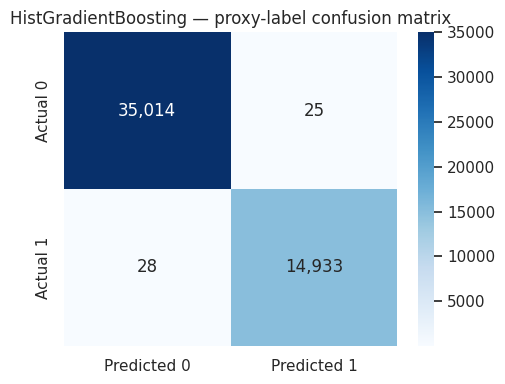

Accuracy: 99.8940%
Precision: 99.8329%
Recall: 99.8128%
ROC-AUC: 0.999997


In [37]:
selected_cls = cls_results["hist_gb"]
cm = np.array([[selected_cls["tn"], selected_cls["fp"]],
               [selected_cls["fn"], selected_cls["tp"]]])

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues",
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"])
plt.title("HistGradientBoosting — proxy-label confusion matrix")
plt.tight_layout()
plt.show()

print("Accuracy:", f"{selected_cls['accuracy']:.4%}")
print("Precision:", f"{selected_cls['precision']:.4%}")
print("Recall:", f"{selected_cls['recall']:.4%}")
print("ROC-AUC:", f"{selected_cls['roc_auc']:.6f}")

### Classifier interpretation

- Held-out accuracy: **0.99894** (about 99.89%).
- Precision: **0.99833**.
- Recall: **0.99813**.
- ROC-AUC: approximately **1.00000**.
- A price-feature ablation (`hist_gb_no_price_features`) lowers accuracy to **0.82394**, showing how much the proxy target depends on price-derived inputs.

The classification output must always be described as a proxy-label recovery score, not an investment success probability.

## 11. Regression results — estimating current asking price

The regression target is the observed current `Price_in_Lakhs` column. The project selected HistGradientBoosting by cross-validated RMSE, but the held-out R² is approximately zero and the result does not beat the mean-price baseline.

No future-price target exists in the source data. Therefore, the 2030 projection is not a learned regression task and is not evaluated as a forecast.

In [38]:
reg_results = metrics["results"]["regression"]
regression_table = pd.DataFrame({
    name: {k: result.get(k) for k in ["rmse", "mae", "r2", "cv_rmse"]}
    for name, result in reg_results.items()
}).T
display(regression_table)

,rmse,mae,r2,cv_rmse
baseline_city_mean,141.195410,122.317930,-0.000032,NaN
baseline_mean,141.193240,122.317776,-0.000001,NaN
ridge,141.205283,122.319194,-0.000172,141.179202
hist_gb,141.196593,122.318291,-0.000049,141.151988


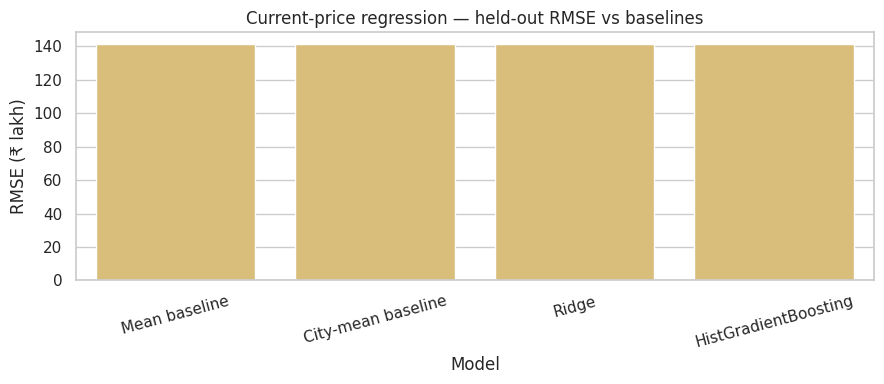

,Model,RMSE (₹ lakh)
0,Mean baseline,141.193240
1,City-mean baseline,141.195410
2,Ridge,141.205283
3,HistGradientBoosting,141.196593


In [39]:
reg_compare = pd.DataFrame({
    "Model": ["Mean baseline", "City-mean baseline", "Ridge", "HistGradientBoosting"],
    "RMSE (₹ lakh)": [
        reg_results["baseline_mean"]["rmse"],
        reg_results["baseline_city_mean"]["rmse"],
        reg_results["ridge"]["rmse"],
        reg_results["hist_gb"]["rmse"]
    ]
})
plt.figure(figsize=(9, 4))
sns.barplot(data=reg_compare, x="Model", y="RMSE (₹ lakh)", color="#E9C46A")
plt.title("Current-price regression — held-out RMSE vs baselines")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
display(reg_compare)

### Regression interpretation

- Selected model RMSE: approximately **₹141.197 lakh**.
- MAE: approximately **₹122.318 lakh**.
- R²: approximately **−0.00005**.
- Mean baseline RMSE: approximately **₹141.193 lakh**.

The selected model does not outperform the mean baseline. The project report explains that price is effectively unrelated to the available attributes in this synthetic-looking dataset. The user-facing estimate should not be treated as a reliable fair-value judgement.

## 12. Feature-importance analysis

The repository uses permutation importance on a held-out sample. The classifier's most important feature is `Price_per_SqFt_Rs`, because the proxy label explicitly depends on price per square foot relative to a city median.

Regression importances are near zero, consistent with the weak regression score. They should not be interpreted as meaningful price drivers.

Calculating permutation importance on a validation sample...


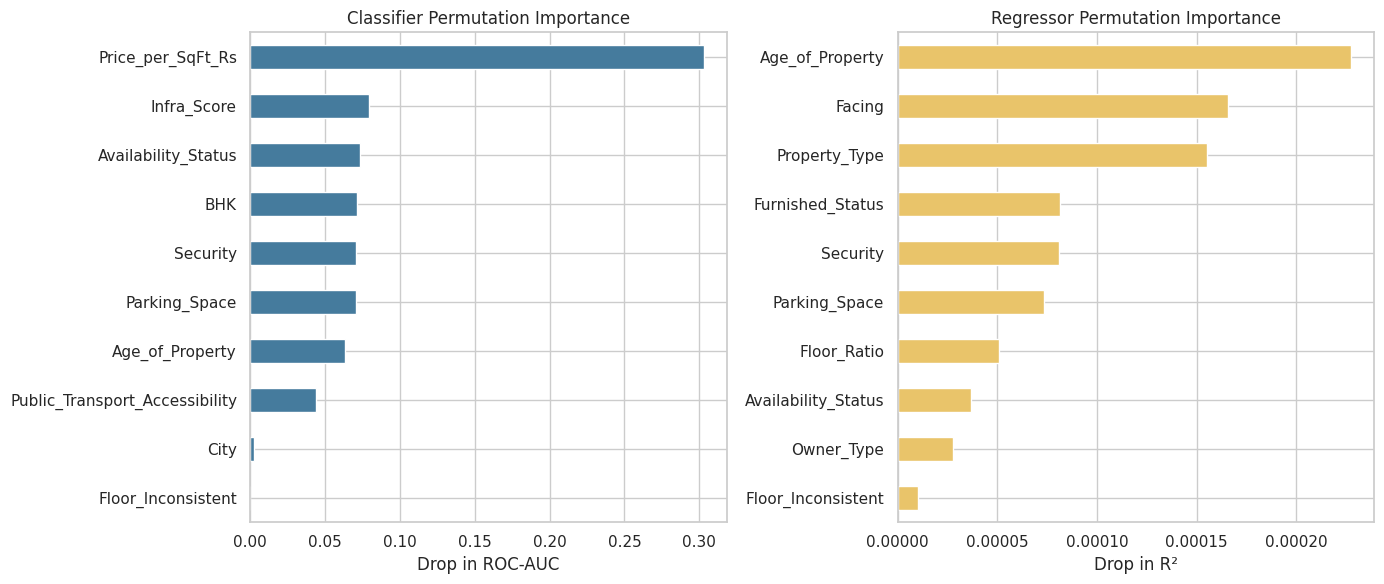

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from src.features import CLS_FEATURES, REG_FEATURES

try:
    importance_cls = pd.Series(metrics["importance"]["classification"]).sort_values().tail(10)
    importance_reg = pd.Series(metrics["importance"]["regression"]).sort_values().tail(10)
except KeyError:
    print("Calculating permutation importance on a validation sample...")
    eval_sample = test_eval.sample(min(2000, len(test_eval)), random_state=42)

    result_cls = permutation_importance(
        clf, eval_sample[CLS_FEATURES], eval_sample["Good_Investment"],
        n_repeats=3, random_state=42, n_jobs=-1
    )
    importance_cls = pd.Series(result_cls.importances_mean, index=CLS_FEATURES).sort_values().tail(10)

    result_reg = permutation_importance(
        reg, eval_sample[REG_FEATURES], eval_sample["Price_in_Lakhs"],
        n_repeats=3, random_state=42, n_jobs=-1
    )
    importance_reg = pd.Series(result_reg.importances_mean, index=REG_FEATURES).sort_values().tail(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
importance_cls.plot(kind="barh", ax=axes[0], color="#457B9D")
axes[0].set_title("Classifier Permutation Importance")
axes[0].set_xlabel("Drop in ROC-AUC")

importance_reg.plot(kind="barh", ax=axes[1], color="#E9C46A")
axes[1].set_title("Regressor Permutation Importance")
axes[1].set_xlabel("Drop in R²")

plt.tight_layout()
plt.show()

## 13. Example property assessment

The following cell constructs a sample from a row in the uploaded dataset and calls the repository's `assess()` function. This uses the saved classifier, regressor and metadata. It reports the rule checklist, classifier probability, current-price model estimate and assumption-based projection as separate output types.

In [ ]:
sample_source = cleaned.iloc[0]

def yes_value(value):
    return str(value).strip().lower() in {"yes", "1", "true"}

sample_inputs = {
    "State": str(sample_source["State"]),
    "City": str(sample_source["City"]),
    "Locality": str(sample_source["Locality"]),
    "Property_Type": str(sample_source["Property_Type"]),
    "BHK": int(sample_source["BHK"]),
    "Size_in_SqFt": float(sample_source["Size_in_SqFt"]),
    "Price_in_Lakhs": float(sample_source["Price_in_Lakhs"]),
    "Year_Built": int(sample_source["Year_Built"]),
    "Furnished_Status": str(sample_source["Furnished_Status"]),
    "Floor_No": int(sample_source["Floor_No"]),
    "Total_Floors": int(sample_source["Total_Floors"]),
    "Nearby_Schools": int(sample_source["Nearby_Schools"]),
    "Nearby_Hospitals": int(sample_source["Nearby_Hospitals"]),
    "Public_Transport_Accessibility": str(sample_source["Public_Transport_Accessibility"]),
    "Parking_Space": yes_value(sample_source["Parking_Space"]),
    "Security": yes_value(sample_source["Security"]),
    "Amenities": [x.strip() for x in str(sample_source["Amenities"]).split(",") if x.strip() and x.strip() != "None"],
    "Facing": str(sample_source["Facing"]),
    "Owner_Type": str(sample_source["Owner_Type"]),
    "Availability_Status": str(sample_source["Availability_Status"]),
}

assessment = assess(sample_inputs, clf, reg, loaded_metadata)
display(pd.Series(sample_inputs, name="Sample property").to_frame())
assessment

### Reading the assessment output

- **Rule label and checklist:** Deterministic results from the project's 8-point screen.
- **Classifier probability:** Model confidence for reproducing the proxy rule, not a probability of investment success.
- **Market estimate:** Learned current-price estimate; in this project it has no useful skill versus the mean baseline.
- **Assumed growth rate and projected price:** Rule-driven scenario calculation, not a validated forecast.

## 14. Five-year scenario calculation

The repository uses a base annual appreciation assumption of 8%, with an overall allowed range of 4%–12%. City percentile, property type, infrastructure score, availability and age adjust the rate, after which it is clipped to that range.

The reference year is 2025, so the five-year horizon ends in **2030**. It is not five years from the current date.

In [ ]:
asking_price = float(sample_inputs["Price_in_Lakhs"])
scenario_rates = [GROWTH_MIN, BASE_GROWTH, GROWTH_MAX]
scenario_values = [float(project_price(asking_price, rate, HORIZON_YEARS)) for rate in scenario_rates]

scenario_table = pd.DataFrame({
    "Scenario": [f"{rate:.0%} per year" for rate in scenario_rates],
    "Assumed annual rate": scenario_rates,
    "Illustrative 2030 value (₹ lakh)": scenario_values,
})
display(scenario_table)

plt.figure(figsize=(8, 4))
sns.barplot(data=scenario_table, x="Scenario", y="Illustrative 2030 value (₹ lakh)", color="#2A9D8F")
plt.axhline(asking_price, color="#E76F51", linestyle="--", label="Current asking price")
plt.title("Illustrative five-year scenarios — arithmetic, not a forecast")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
RUN_FULL_TRAINING = False
if RUN_FULL_TRAINING:
    from src.train import main as train_models
    original_cwd = Path.cwd()
    train_models(data=str(DATA_PATH), out_dir=str(REPO_DIR))
    os.chdir(original_cwd)
    print("Training run completed in the temporary Colab repository clone.")
else:
    print("Skipped: using the saved models and recorded evaluation results from the repository.")

## 16. Limitations and responsible interpretation

### Dataset limitations

- Numeric values and category shares are unusually uniform and balanced.
- Asking price is almost uncorrelated with size and other raw attributes.
- A large share of floor values are physically inconsistent.
- Locality IDs repeat across cities and are not geographic neighbourhoods.
- Some property type, floor and construction-status combinations are implausible.
- The source has no sale-date history, future price, rental yield or realized investment outcome.

### Model limitations

- The classifier learns a rule-generated label, not actual investment success.
- The regression model does not outperform a mean-price baseline.
- The five-year projection is an assumption-based arithmetic scenario and has no measured forecast accuracy.
- Cross-validation uses a training subsample for runtime efficiency; the held-out test set is used for final reporting.
- Results describe the supplied dataset and should not be generalized to real property markets.

### Future improvements

1. Use verified, representative property transaction data.
2. Add time-stamped sale prices, rental yields and realized returns.
3. Validate across multiple cities and time periods.
4. Rebuild the targets around observed investment outcomes.
5. Evaluate future-price forecasts against genuinely held-out future transactions.

## 18. Conclusion

The Real Estate Investment Advisor integrates data auditing, exploratory analysis, feature engineering, rule-based screening, machine-learning evaluation and an interactive Streamlit deployment.

The project demonstrates an important modelling discipline: clearly distinguish learned results from deterministic rules and assumptions. The classifier recovers a rule-generated target with very high accuracy, while the current-price regressor does not demonstrate useful predictive skill on this dataset. The five-year output is an illustrative scenario, not a learned forecast.

The next meaningful improvement is not to overstate model performance, but to replace the synthetic-looking input with verified historical property, rental and investment-outcome data.

---

**End of Real Estate Investment Advisor project notebook**  
Author: **Kusuma Ramesh**  
Repository: https://github.com/Kusuma-Ramesh/real_estate_advisor